# Ptosis Detection Program using Webcam Capture

In [1]:
import cv2
import dlib
from imutils import face_utils
from scipy.spatial import distance as dist
import math
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import json
import time

drive.mount('/content/drive')

path='/content/drive/MyDrive/shape_predictor_68_face_landmarks.dat'


Mounted at /content/drive


### Ptosis Detection Helper Functions

These functions handle the core logic for calculating Eye Aspect Ratios (EAR) and providing a diagnosis based on these values.

In [2]:
EYE_AR_THRESH = 0.275

face_detector = dlib.get_frontal_face_detector()
eyes_detector = dlib.shape_predictor(path)

def eye_aspect_ratio(eye):
    A = dist.euclidean(eye[1], eye[5])
    B = dist.euclidean(eye[2], eye[4])
    C = dist.euclidean(eye[0], eye[3])
    ear = (A + B) / (2.0 * C)
    return ear

def detect_eye_features(eye_points, gray_frame, color_frame):
    # Calculate centroid of the eye for cropping
    eye_center_x = int(np.mean(eye_points[:, 0]))
    eye_center_y = int(np.mean(eye_points[:, 1]))

    # Define a rectangular region of interest (ROI) around the eye
    x_min, y_min = np.min(eye_points, axis=0)
    x_max, y_max = np.max(eye_points, axis=0)
    # Add some padding to make sure we capture the entire iris/pupil
    padding = 10 # Reverted padding
    x_min = max(0, x_min - padding)
    y_min = max(0, y_min - padding)
    x_max = min(gray_frame.shape[1], x_max + padding)
    y_max = min(gray_frame.shape[0], y_max + padding)

    eye_roi_gray = gray_frame[y_min:y_max, x_min:x_max]

    pupil_radius = -1
    iris_radius = -1
    iris_color = (0, 0, 0) # Default to black (RGB)
    pupil_coords = None

    if eye_roi_gray.size == 0 or x_min >= x_max or y_min >= y_max:
        return pupil_radius, iris_radius, iris_color, pupil_coords

    # Pupil Detection (using adaptive thresholding and morphological operations)
    # Apply Gaussian blur to smooth the image and reduce noise
    blurred_eye_roi = cv2.GaussianBlur(eye_roi_gray, (9, 9), 0) # Kept blur kernel size

    # Use adaptive thresholding to find the pupil
    # Adaptive thresholding is more robust to lighting variations
    thresh = cv2.adaptiveThreshold(blurred_eye_roi, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 12) # Changed C from 2 to 12

    # Morphological operations to clean up the thresholded image and fill small holes in the pupil
    kernel = np.ones((3,3),np.uint8) # Small kernel
    thresh = cv2.erode(thresh, kernel, iterations=1)  # Erode to remove noise
    thresh = cv2.dilate(thresh, kernel, iterations=1) # Dilate to fill small gaps, maintaining size

    # Find contours
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if contours:
        # Sort contours by area and pick the largest one (likely the pupil)
        pupil_contour = max(contours, key=cv2.contourArea)

        # Fit a minimum enclosing circle to the pupil contour
        ((px, py), pr) = cv2.minEnclosingCircle(pupil_contour)
        pupil_radius = round(pr)

        # Adjust pupil center to original frame coordinates
        pupil_center_x_orig = int(px) + x_min
        pupil_center_y_orig = int(py) + y_min
        pupil_coords = (pupil_center_x_orig, pupil_center_y_orig)

        # Iris Detection (Approximation)
        if pupil_radius > 0:
            iris_radius = pupil_radius * 2.2 # Changed iris ratio from 2.0 to 2.2
        else:
            eye_width = dist.euclidean(eye_points[0], eye_points[3])
            iris_radius = eye_width * 0.4

        # Iris Color Calculation
        if pupil_coords and iris_radius > 0:
            # Create a circular mask for the iris in the original frame coordinates
            iris_mask = np.zeros(color_frame.shape[:2], dtype="uint8")
            cv2.circle(iris_mask, pupil_coords, int(iris_radius), 255, -1)

            # Get all pixel values from the original color_frame that fall within the iris_mask
            row_indices, col_indices = np.where(iris_mask == 255)
            iris_pixels = color_frame[row_indices, col_indices]

            if iris_pixels.size > 0:
                avg_color = np.mean(iris_pixels, axis=0) # Reverted to simple average
                # Convert BGR (OpenCV default) to RGB and round to int
                iris_color = (int(round(avg_color[2])), int(round(avg_color[1])), int(round(avg_color[0])))

    return pupil_radius, iris_radius, iris_color, pupil_coords

def process_webcam_frame_analysis(frame, all_left_ears, all_right_ears, all_left_mrd1_values, all_left_mrd2_values, all_right_mrd1_values, all_right_mrd2_values):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = face_detector(gray)
    annotated_frame = frame.copy()

    current_left_ear = -1.0
    current_right_ear = -1.0
    left_iris_c = (0,0,0)
    right_iris_c = (0,0,0)
    left_pupil_r = -1 # Reset initial value
    left_iris_r = -1 # Reset initial value
    right_pupil_r = -1 # Reset initial value
    right_iris_r = -1 # Reset initial value
    current_left_mrd1 = -1.0
    current_left_mrd2 = -1.0
    current_right_mrd1 = -1.0
    current_right_mrd2 = -1.0
    current_left_eye_diagonal_diameter_pixels = -1.0 # Initialize new variable
    current_right_eye_diagonal_diameter_pixels = -1.0 # Initialize new variable

    for face in faces:
        eyes_dlib_shape = eyes_detector(gray, face)

        for n in range(36, 48):
            x = eyes_dlib_shape.part(n).x
            y = eyes_dlib_shape.part(n).y
            cv2.circle(annotated_frame, (x, y), 1, (0, 255, 255), 1)

        eyes_np = face_utils.shape_to_np(eyes_dlib_shape)

        (lStart, lEnd) = face_utils.FACIAL_LANDMARKS_IDXS["left_eye"]
        (rStart, rEnd) = face_utils.FACIAL_LANDMARKS_IDXS["right_eye"]

        leftEye_points = eyes_np[lStart:lEnd]
        current_left_ear = eye_aspect_ratio(leftEye_points)
        if current_left_ear > 0:
            all_left_ears.append(current_left_ear)

        rightEye_points = eyes_np[rStart:rEnd]
        current_right_ear = eye_aspect_ratio(rightEye_points)
        if current_right_ear > 0:
            all_right_ears.append(current_right_ear)

        # Detect pupil, iris and color for left eye
        left_pupil_r, left_iris_r, left_iris_c, left_pupil_coords = detect_eye_features(leftEye_points, gray, annotated_frame)
        # Detect pupil, iris and color for right eye
        right_pupil_r, right_iris_r, right_iris_c, right_pupil_coords = detect_eye_features(rightEye_points, gray, annotated_frame)

        # Calculate MRD1 and MRD2 for left eye
        if left_pupil_coords is not None:
            # Left eye landmarks: 36-41 (indices 0-5 in leftEye_points)
            # Upper eyelid: landmarks 37, 38 (indices 1, 2)
            # Lower eyelid: landmarks 40, 41 (indices 4, 5)
            upper_lid_y_left = min(leftEye_points[1][1], leftEye_points[2][1])
            lower_lid_y_left = max(leftEye_points[4][1], leftEye_points[5][1])
            pupil_y_left = left_pupil_coords[1]

            current_left_mrd1 = pupil_y_left - upper_lid_y_left
            current_left_mrd2 = lower_lid_y_left - pupil_y_left

            if current_left_mrd1 > 0: # Ensure valid positive distance
                all_left_mrd1_values.append(current_left_mrd1)
            if current_left_mrd2 > 0: # Ensure valid positive distance
                all_left_mrd2_values.append(current_left_mrd2)

        # Calculate MRD1 and MRD2 for right eye
        if right_pupil_coords is not None:
            # Right eye landmarks: 42-47 (indices 0-5 in rightEye_points)
            # Upper eyelid: landmarks 43, 44 (indices 1, 2)
            # Lower eyelid: landmarks 46, 47 (indices 4, 5)
            upper_lid_y_right = min(rightEye_points[1][1], rightEye_points[2][1])
            lower_lid_y_right = max(rightEye_points[4][1], rightEye_points[5][1])
            pupil_y_right = right_pupil_coords[1]

            current_right_mrd1 = pupil_y_right - upper_lid_y_right
            current_right_mrd2 = lower_lid_y_right - pupil_y_right

            if current_right_mrd1 > 0: # Ensure valid positive distance
                all_right_mrd1_values.append(current_right_mrd1)
            if current_right_mrd2 > 0: # Ensure valid positive distance
                all_right_mrd2_values.append(current_right_mrd2)

        # Calculate new 'IRIS Diameter' based on diagonal eye opening for left eye
        left_diag1 = dist.euclidean(leftEye_points[1], leftEye_points[4]) # Landmark 37 to 40
        left_diag2 = dist.euclidean(leftEye_points[2], leftEye_points[5]) # Landmark 38 to 41
        current_left_eye_diagonal_diameter_pixels = (left_diag1 + left_diag2) / 2.0

        # Calculate new 'IRIS Diameter' based on diagonal eye opening for right eye
        right_diag1 = dist.euclidean(rightEye_points[1], rightEye_points[4]) # Landmark 43 to 46
        right_diag2 = dist.euclidean(rightEye_points[2], rightEye_points[5]) # Landmark 44 to 47
        current_right_eye_diagonal_diameter_pixels = (right_diag1 + right_diag2) / 2.0

        # Removed drawing of pupil and iris circles
        # Removed text overlays for pupil, iris size and color

        cv2.putText(annotated_frame, f"L-EAR: {current_left_ear:.2f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        cv2.putText(annotated_frame, f"R-EAR: {current_right_ear:.2f}", (10, 60),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        cv2.putText(annotated_frame, f"L-MRD1: {current_left_mrd1:.2f}", (10, 90),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.putText(annotated_frame, f"L-MRD2: {current_left_mrd2:.2f}", (10, 120),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.putText(annotated_frame, f"R-MRD1: {current_right_mrd1:.2f}", (10, 150),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.putText(annotated_frame, f"R-MRD2: {current_right_mrd2:.2f}", (10, 180),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        break

    return annotated_frame, current_left_ear, current_right_ear, left_iris_c, right_iris_c, left_pupil_r, left_iris_r, right_pupil_r, right_iris_r, current_left_mrd1, current_left_mrd2, current_right_mrd1, current_right_mrd2, current_left_eye_diagonal_diameter_pixels, current_right_eye_diagonal_diameter_pixels

def provide_ptosis_diagnosis(all_left_ears, all_right_ears, EYE_AR_THRESH_val, all_left_mrd1_values, all_left_mrd2_values, all_right_mrd1_values, all_right_mrd2_values):
    average_left_EAR = 0
    if len(all_left_ears) > 0:
        average_left_EAR = sum(all_left_ears) / len(all_left_ears)

    average_right_EAR = 0
    if len(all_right_ears) > 0:
        average_right_EAR = sum(all_right_ears) / len(all_right_ears)

    print('\nDiagnosis:')

    print(f"Average Left Eye Aspect Ratio: {average_left_EAR:.2f}")
    if average_left_EAR > 0:
        if average_left_EAR < EYE_AR_THRESH_val:
            print('Ptosis suspected in Left Eye, please consult a medical professional.')
        else:
            print('No Ptosis suspected in Left Eye.')
    else:
        print('Unable to diagnose Left Eye (no valid EAR data captured).')

    print(f"Average Right Eye Aspect Ratio: {average_right_EAR:.2f}")
    if average_right_EAR > 0:
        if average_right_EAR < EYE_AR_THRESH_val:
            print('Ptosis suspected in Right Eye, please consult a medical professional.')
        else:
            print('No Ptosis suspected in Right Eye.')
    else:
        print('Unable to diagnose Right Eye (no valid EAR data captured).')

    # Calculate and print average MRD values
    avg_left_mrd1 = calculate_average_size(all_left_mrd1_values)
    avg_left_mrd2 = calculate_average_size(all_left_mrd2_values)
    avg_right_mrd1 = calculate_average_size(all_right_mrd1_values)
    avg_right_mrd2 = calculate_average_size(all_right_mrd2_values)

    print(f"\nAverage Left MRD1 (Pupil to Upper Eyelid): {(avg_left_mrd1 * MM_PER_PIXEL_APPROX):.2f} mm")
    print(f"Average Left MRD2 (Pupil to Lower Eyelid): {(avg_left_mrd2 * MM_PER_PIXEL_APPROX):.2f} mm")
    print(f"Average Right MRD1 (Pupil to Upper Eyelid): {(avg_right_mrd1 * MM_PER_PIXEL_APPROX):.2f} mm")
    print(f"Average Right MRD2 (Pupil to Lower Eyelid): {(avg_right_mrd2 * MM_PER_PIXEL_APPROX):.2f} mm")

### Automated Webcam Frame Capture and Ptosis Analysis

This section handles the automated capture of frames from your webcam, processes each frame for ptosis detection, and then provides a final diagnosis.


Ready to capture 3 frames. Each frame will be captured automatically.

Capturing frame 1/3...


<IPython.core.display.Javascript object>

Saved to photo_0.jpg


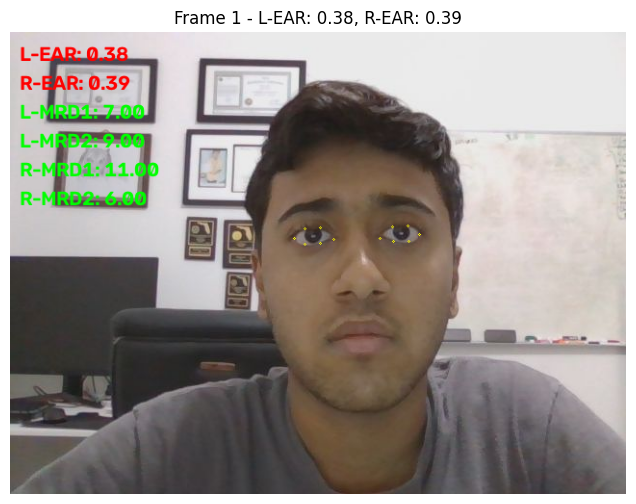


--- Frame captured. Moving to next... ---

Capturing frame 2/3...


<IPython.core.display.Javascript object>

Saved to photo_1.jpg


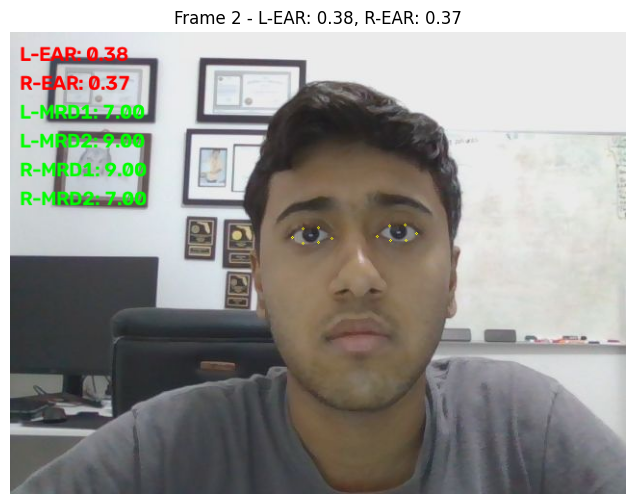


--- Frame captured. Moving to next... ---

Capturing frame 3/3...


<IPython.core.display.Javascript object>

Saved to photo_2.jpg


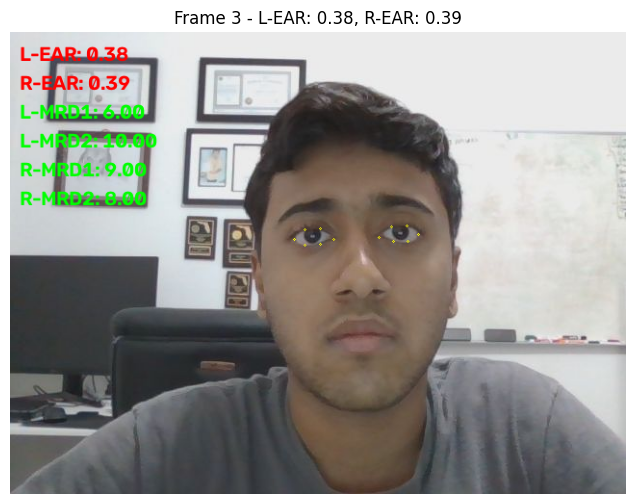


Diagnosis:
Average Left Eye Aspect Ratio: 0.38
No Ptosis suspected in Left Eye.
Average Right Eye Aspect Ratio: 0.38
No Ptosis suspected in Right Eye.

Average Left MRD1 (Pupil to Upper Eyelid): 3.33 mm
Average Left MRD2 (Pupil to Lower Eyelid): 4.67 mm
Average Right MRD1 (Pupil to Upper Eyelid): 4.83 mm
Average Right MRD2 (Pupil to Lower Eyelid): 3.50 mm

Average Left Iris Color (RGB): (94, 84, 75)
Average Right Iris Color (RGB): (93, 83, 76)
Average Left Eye Opening Diagonal Diameter (landmarks): 11.09 mm
Average Right Eye Opening Diagonal Diameter (landmarks): 11.20 mm


In [4]:
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      let stream;
      try {
        stream = await navigator.mediaDevices.getUserMedia({video: true});
      } catch (err) {
        if (err.name === 'NotAllowedError' || err.name === 'PermissionDeniedError') {
          return JSON.stringify({"error": "CAMERA_ACCESS_DENIED", "message": err.message});
        }
        throw err;
      }

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Reduced the delay for faster frame capture.
      // For truly continuous high-frame-rate streaming, the JavaScript
      // would need to be refactored to keep the stream active and capture
      // frames without stopping and starting it repeatedly.
      await new Promise(resolve => setTimeout(resolve, 50)); // Original was 500ms

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))

  if isinstance(data, str) and data.startswith('{') and '"error"' in data:
    try:
      error_info = json.loads(data)
      if error_info.get("error") == "CAMERA_ACCESS_DENIED":
        raise PermissionError(f"Camera access was denied: {error_info.get('message', 'No message provided')}. Please ensure you allow camera access when prompted.")
      else:
        raise ValueError(f"Unknown JavaScript error: {data}")
    except json.JSONDecodeError:
      pass

  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

def calculate_average_rgb_color(rgb_color_list):
    if not rgb_color_list:
        return (0, 0, 0) # Return black if no colors detected
    r_sum, g_sum, b_sum = 0, 0, 0
    for r, g, b in rgb_color_list:
        r_sum += r
        g_sum += g
        b_sum += b
    count = len(rgb_color_list)
    return (int(r_sum / count), int(g_sum / count), int(b_sum / count))

# Helper function to calculate average of a list of numbers
def calculate_average_size(size_list):
    if not size_list:
        return 0.0
    return sum(size_list) / len(size_list)

# Approximate conversion factor for pixels to millimeters.
# This value is a placeholder and should ideally be calibrated for accuracy.
# For example, if a known object of 10mm appears to be 100 pixels, then MM_PER_PIXEL_APPROX = 10/100 = 0.1
MM_PER_PIXEL_APPROX = 0.5 # Placeholder value

# Handle num_frames_str parsing separately for clearer error messages
try:
    num_frames_str = 3
    #num_frames_str = input("Enter the number of frames to capture (e.g., 3 for a short sequence): ")
    num_frames_to_capture = int(num_frames_str)
except ValueError:
    print("Invalid input. Please enter an integer for the number of frames.")
    num_frames_to_capture = 0 # Set to 0 to skip further processing

if num_frames_to_capture > 0:
    try:
        if num_frames_to_capture <= 0:
            print("Number of frames must be positive. Skipping analysis.")
        else:
            all_left_ears_session = []
            all_right_ears_session = []
            all_left_iris_colors = []
            all_right_iris_colors = []
            all_left_pupil_sizes = [] # Initialize list to store left pupil radii
            all_left_iris_sizes = []  # Initialize list to store left iris radii
            all_right_pupil_sizes = [] # Initialize list to store right pupil radii
            all_right_iris_sizes = [] # Initialize list to store right iris radii
            all_left_mrd1_values = [] # Initialize list to store left MRD1 values
            all_left_mrd2_values = [] # Initialize list to store left MRD2 values
            all_right_mrd1_values = [] # Initialize list to store right MRD1 values
            all_right_mrd2_values = [] # Initialize list to store right MRD2 values
            all_left_eye_diagonal_diameters = [] # Initialize list for new diagonal measurement
            all_right_eye_diagonal_diameters = [] # Initialize list for new diagonal measurement

            print(f"\nReady to capture {num_frames_to_capture} frames. Each frame will be captured automatically.\n")

            for i in range(num_frames_to_capture):
                print(f"Capturing frame {i+1}/{num_frames_to_capture}...")
                filename = take_photo(f'photo_{i}.jpg')
                print(f'Saved to {filename}')

                img = cv2.imread(filename)
                if img is None:
                    print(f"Error: Could not read image {filename}. Skipping this frame.")
                    continue

                # Unpack the additional return values for pupil and iris radii, MRD values, and new diagonal measurements
                annotated_img, current_left_ear, current_right_ear, left_iris_c, right_iris_c, \
                left_pupil_r, left_iris_r, right_pupil_r, right_iris_r, \
                current_left_mrd1, current_left_mrd2, current_right_mrd1, current_right_mrd2, \
                current_left_eye_diagonal_diameter_pixels, current_right_eye_diagonal_diameter_pixels = process_webcam_frame_analysis(
                    img, all_left_ears_session, all_right_ears_session, \
                    all_left_mrd1_values, all_left_mrd2_values, all_right_mrd1_values, all_right_mrd2_values
                )

                if left_iris_c != (0,0,0): # Only add if color was successfully detected (not default black)
                    all_left_iris_colors.append(left_iris_c)
                if right_iris_c != (0,0,0): # Only add if color was successfully detected (not default black)
                    all_right_iris_colors.append(right_iris_c)

                # Collect pupil and iris sizes
                if left_pupil_r > 0:
                    all_left_pupil_sizes.append(left_pupil_r)
                if left_iris_r > 0:
                    all_left_iris_sizes.append(left_iris_r)
                if right_pupil_r > 0:
                    all_right_pupil_sizes.append(right_pupil_r)
                if right_iris_r > 0:
                    all_right_iris_sizes.append(right_iris_r)

                # Collect new diagonal measurements
                if current_left_eye_diagonal_diameter_pixels > 0:
                    all_left_eye_diagonal_diameters.append(current_left_eye_diagonal_diameter_pixels)
                if current_right_eye_diagonal_diameter_pixels > 0:
                    all_right_eye_diagonal_diameters.append(current_right_eye_diagonal_diameter_pixels)


                plt.figure(figsize=(8, 6))
                plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
                plt.title(f'Frame {i+1} - L-EAR: {current_left_ear:.2f}, R-EAR: {current_right_ear:.2f}')
                plt.axis('off')
                plt.show()

                if i < num_frames_to_capture - 1:
                    print("\n--- Frame captured. Moving to next... ---\n")

            if all_left_ears_session or all_right_ears_session:
                provide_ptosis_diagnosis(all_left_ears_session, all_right_ears_session, EYE_AR_THRESH, \
                                        all_left_mrd1_values, all_left_mrd2_values, all_right_mrd1_values, all_right_mrd2_values)

                avg_left_iris_color = calculate_average_rgb_color(all_left_iris_colors)
                avg_right_iris_color = calculate_average_rgb_color(all_right_iris_colors)

                print(f"\nAverage Left Iris Color (RGB): {avg_left_iris_color}")
                print(f"Average Right Iris Color (RGB): {avg_right_iris_color}")

                # Calculate and display average pupil/iris sizes and iris diameter in mm
                avg_left_pupil_size = calculate_average_size(all_left_pupil_sizes)
                avg_left_iris_size = calculate_average_size(all_left_iris_sizes)
                avg_right_pupil_size = calculate_average_size(all_right_pupil_sizes)
                avg_right_iris_size = calculate_average_size(all_right_iris_sizes)

                #print(f"\nAverage Left Pupil Radius (pixels): {avg_left_pupil_size:.2f}")
                #print(f"Average Left Iris Radius (pixels): {avg_left_iris_size:.2f}")
                #print(f"Average Right Pupil Radius (pixels): {avg_right_pupil_size:.2f}")
                #print(f"Average Right Iris Radius (pixels): {avg_right_iris_size:.2f}")

                # Calculate iris diameter in mm (Corrected: multiply radius by 2 to get diameter)
                left_iris_diameter_mm = (avg_left_iris_size * 2) * MM_PER_PIXEL_APPROX
                right_iris_diameter_mm = (avg_right_iris_size * 2) * MM_PER_PIXEL_APPROX

                #print(f"Average Left Iris Diameter (from pupil): {left_iris_diameter_mm:.2f} mm")
                #print(f"Average Right Iris Diameter (from pupil): {right_iris_diameter_mm:.2f} mm")

                # Calculate and display new eye opening diagonal diameter in mm
                avg_left_eye_diag_diam_pixels = calculate_average_size(all_left_eye_diagonal_diameters)
                avg_right_eye_diag_diam_pixels = calculate_average_size(all_right_eye_diagonal_diameters)

                left_eye_diag_diam_mm = avg_left_eye_diag_diam_pixels * MM_PER_PIXEL_APPROX
                right_eye_diag_diam_mm = avg_right_eye_diag_diam_pixels * MM_PER_PIXEL_APPROX

                print(f"Average Left Eye Opening Diagonal Diameter (landmarks): {left_eye_diag_diam_mm:.2f} mm")
                print(f"Average Right Eye Opening Diagonal Diameter (landmarks): {right_eye_diag_diam_mm:.2f} mm")

            else:
                print("No valid eye data captured for diagnosis.")

    except PermissionError as e:
      print(f"Error: {e}")
    except Exception as err:
      print(f"An unexpected error occurred: {str(err)}")